In [1]:
import os
import shutil
import hashlib

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image

from sklearn.model_selection import train_test_split

In [2]:
DATASET_PATH = "../data/Kidney Cancer"
CLEAN_PATH = "../data/Kidney Cancer Clean"

classes = [
    "Normal",
    "Tumor"
]

print("Original dataset:", DATASET_PATH)
print("Clean dataset:", CLEAN_PATH)
print("Classes:", classes)

Original dataset: ../data/Kidney Cancer
Clean dataset: ../data/Kidney Cancer Clean
Classes: ['Normal', 'Tumor']


In [3]:
image_paths = []
image_labels = []

for cls in classes:

    class_path = os.path.join(
        DATASET_PATH,
        cls
    )

    for file in os.listdir(class_path):

        image_path = os.path.join(
            class_path,
            file
        )

        if os.path.isfile(image_path):

            image_paths.append(image_path)
            image_labels.append(cls)

print("Total images:", len(image_paths))

print("\nClass distribution:")

for cls in classes:
    print(
        cls,
        ":",
        image_labels.count(cls)
    )

Total images: 10000

Class distribution:
Normal : 5000
Tumor : 5000


### Identify duplicate groups

In [4]:
hash_groups = {}

for image_path in image_paths:

    with open(image_path, "rb") as f:
        file_hash = hashlib.md5(
            f.read()
        ).hexdigest()

    if file_hash not in hash_groups:
        hash_groups[file_hash] = []

    hash_groups[file_hash].append(
        image_path
    )

duplicate_groups = {
    file_hash: paths
    for file_hash, paths in hash_groups.items()
    if len(paths) > 1
}

print("Duplicate groups:", len(duplicate_groups))
print(
    "Images involved in duplicates:",
    sum(len(paths) for paths in duplicate_groups.values())
)

Duplicate groups: 75
Images involved in duplicates: 150


### Create cleaned dataset

In [5]:
os.makedirs(CLEAN_PATH, exist_ok=True)

for cls in classes:

    os.makedirs(
        os.path.join(CLEAN_PATH, cls),
        exist_ok=True
    )

In [6]:
kept_hashes = set()

cleaned_paths = []
cleaned_labels = []

for image_path, label in zip(
    image_paths,
    image_labels
):

    with open(image_path, "rb") as f:
        file_hash = hashlib.md5(
            f.read()
        ).hexdigest()

    if file_hash in kept_hashes:
        continue

    kept_hashes.add(file_hash)

    cleaned_paths.append(image_path)
    cleaned_labels.append(label)

print("Images after duplicate removal:", len(cleaned_paths))

print("\nClass distribution after duplicate removal:")

for cls in classes:
    print(
        cls,
        ":",
        cleaned_labels.count(cls)
    )

Images after duplicate removal: 9925

Class distribution after duplicate removal:
Normal : 4925
Tumor : 5000


In [7]:
for image_path, label in zip(
    cleaned_paths,
    cleaned_labels
):

    filename = os.path.basename(image_path)

    destination = os.path.join(
        CLEAN_PATH,
        label,
        filename
    )

    shutil.copy2(
        image_path,
        destination
    )

print("Cleaned dataset created successfully.")

Cleaned dataset created successfully.


In [8]:
for cls in classes:

    class_path = os.path.join(
        CLEAN_PATH,
        cls
    )

    count = len([
        file for file in os.listdir(class_path)
        if os.path.isfile(
            os.path.join(class_path, file)
        )
    ])

    print(f"{cls}: {count}")

print(
    "\nTotal:",
    sum(
        len(os.listdir(
            os.path.join(CLEAN_PATH, cls)
        ))
        for cls in classes
    )
)

Normal: 4925
Tumor: 5000

Total: 9925


### Load cleaned dataset

In [9]:
image_paths = []
image_labels = []

for cls in classes:

    class_path = os.path.join(
        CLEAN_PATH,
        cls
    )

    for file in os.listdir(class_path):

        image_path = os.path.join(
            class_path,
            file
        )

        if os.path.isfile(image_path):
            image_paths.append(image_path)
            image_labels.append(cls)

print("Total cleaned images:", len(image_paths))

Total cleaned images: 9925


In [10]:
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    stratify=image_labels,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 6947
Validation: 1489
Test: 1489


In [11]:
print("Train distribution:")
print(pd.Series(y_train).value_counts())

print("\nValidation distribution:")
print(pd.Series(y_val).value_counts())

print("\nTest distribution:")
print(pd.Series(y_test).value_counts())

Train distribution:
Tumor     3500
Normal    3447
Name: count, dtype: int64

Validation distribution:
Tumor     750
Normal    739
Name: count, dtype: int64

Test distribution:
Tumor     750
Normal    739
Name: count, dtype: int64


In [12]:
label_map = {
    "Normal": 0,
    "Tumor": 1
}

y_train_encoded = [
    label_map[label]
    for label in y_train
]

y_val_encoded = [
    label_map[label]
    for label in y_val
]

y_test_encoded = [
    label_map[label]
    for label in y_test
]

print("Label mapping:", label_map)

print("\nEncoded train labels:")
print(pd.Series(y_train_encoded).value_counts())

Label mapping: {'Normal': 0, 'Tumor': 1}

Encoded train labels:
1    3500
0    3447
Name: count, dtype: int64


### Image preprocessing

In [13]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

def load_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    return image, label

In [14]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(
        0.1,
        0.1
    )
])

In [15]:
def augment_image(image, label):

    image = data_augmentation(
        tf.expand_dims(image, axis=0),
        training=True
    )

    image = tf.squeeze(
        image,
        axis=0
    )

    return image, label

### Create TensorFlow datasets

In [16]:
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train_encoded)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val_encoded)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test_encoded)
)

In [17]:
train_dataset = train_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_dataset = val_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

In [18]:
train_dataset = train_dataset.shuffle(
    buffer_size=len(X_train),
    seed=42
)

train_dataset = train_dataset.map(
    augment_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

In [19]:
train_dataset = train_dataset.batch(
    BATCH_SIZE
).prefetch(
    tf.data.AUTOTUNE
)

val_dataset = val_dataset.batch(
    BATCH_SIZE
).prefetch(
    tf.data.AUTOTUNE
)

test_dataset = test_dataset.batch(
    BATCH_SIZE
).prefetch(
    tf.data.AUTOTUNE
)

In [20]:
for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Label dtype:", labels.dtype)

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int32'>


### Import EfficientNetB0

In [21]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

In [22]:
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = models.Sequential([
    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.3),

    layers.Dense(
        1,
        activation="sigmoid"
    )
])

In [23]:
model.compile(
    optimizer=Adam(
        learning_rate=1e-4
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [24]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [25]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

In [26]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=[
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/20


C:\Users\shiva\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


435/435 ━━━━━━━━━━━━━━━━━━━━ 444s 894ms/step - accuracy: 0.7970 - loss: 0.4368 - val_accuracy: 0.8825 - val_loss: 0.2772 - learning_rate: 1.0000e-04
Epoch 2/20
435/435 ━━━━━━━━━━━━━━━━━━━━ 384s 850ms/step - accuracy: 0.8926 - loss: 0.2734 - val_accuracy: 0.9261 - val_loss: 0.2074 - learning_rate: 1.0000e-04
Epoch 3/20
435/435 ━━━━━━━━━━━━━━━━━━━━ 363s 814ms/step - accuracy: 0.9144 - loss: 0.2206 - val_accuracy: 0.9060 - val_loss: 0.1997 - learning_rate: 1.0000e-04
Epoch 4/20
435/435 ━━━━━━━━━━━━━━━━━━━━ 357s 805ms/step - accuracy: 0.9264 - loss: 0.1975 - val_accuracy: 0.9416 - val_loss: 0.1559 - learning_rate: 1.0000e-04
Epoch 5/20
435/435 ━━━━━━━━━━━━━━━━━━━━ 355s 800ms/step - accuracy: 0.9319 - loss: 0.1751 - val_accuracy: 0.9402 - val_loss: 0.1473 - learning_rate: 1.0000e-04
Epoch 6/20
435/435 ━━━━━━━━━━━━━━━━━━━━ 358s 806ms/step - accuracy: 0.9395 - loss: 0.1614 - val_accuracy: 0.9416 - val_loss: 0.1408 - learning_rate: 1.0000e-04
Epoch 7/20
435/435 ━━━━━━━━━━━━━━━━━━━━ 359s 807ms/

In [27]:
test_loss, test_accuracy = model.evaluate(
    test_dataset,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 65s 692ms/step - accuracy: 0.9738 - loss: 0.0724
Test Loss: 0.07242053002119064
Test Accuracy: 0.9738079309463501


In [28]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)

    predicted_labels = (
        predictions.ravel() >= 0.5
    ).astype(int)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Classification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Normal", "Tumor"]
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_true,
        y_pred
    )
)

Classification Report:
              precision    recall  f1-score   support

      Normal       0.97      0.98      0.97       739
       Tumor       0.98      0.97      0.97       750

    accuracy                           0.97      1489
   macro avg       0.97      0.97      0.97      1489
weighted avg       0.97      0.97      0.97      1489

Confusion Matrix:
[[726  13]
 [ 26 724]]


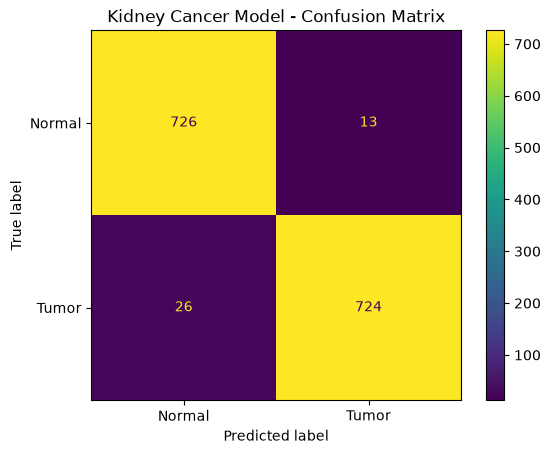

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Tumor"]
)

disp.plot()
plt.title("Kidney Cancer Model - Confusion Matrix")
plt.show()

In [30]:
import os

os.makedirs("../models", exist_ok=True)

model.save("../models/kidney_cancer_model.keras")

print("Kidney model saved successfully.")

Kidney model saved successfully.


In [31]:
model_path = "../models/kidney_cancer_model.keras"

print("Model exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print("Model path:", model_path)
    print(
        "Model size:",
        round(os.path.getsize(model_path) / (1024 * 1024), 2),
        "MB"
    )

Model exists: True
Model path: ../models/kidney_cancer_model.keras
Model size: 18.14 MB


In [32]:
import tensorflow as tf
import numpy as np

IMG_SIZE = (224, 224)

class_names = [
    "Normal",
    "Tumor"
]

def predict_kidney_image(image_path):

    image = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    image = tf.expand_dims(
        image,
        axis=0
    )

    prediction = model.predict(
        image,
        verbose=0
    )[0][0]

    predicted_index = int(prediction >= 0.5)

    predicted_class = class_names[predicted_index]

    confidence = (
        prediction
        if predicted_index == 1
        else 1 - prediction
    )

    return predicted_class, float(confidence)

In [33]:
test_image = X_test[0]

prediction, confidence = predict_kidney_image(
    test_image
)

print("Image:", test_image)
print("Prediction:", prediction)
print("Confidence:", round(confidence * 100, 2), "%")

Image: ../data/Kidney Cancer Clean\Normal\kidney_normal_2721.jpg
Prediction: Tumor
Confidence: 79.87 %


In [34]:
for image_path in X_test[:10]:

    prediction, confidence = predict_kidney_image(
        image_path
    )

    print(
        os.path.basename(image_path),
        "→",
        prediction,
        f"({confidence * 100:.2f}%)"
    )

kidney_normal_2721.jpg → Tumor (79.87%)
kidney_normal_3466.jpg → Normal (99.54%)
kidney_tumor_4602.jpg → Tumor (74.70%)
kidney_normal_3848.jpg → Normal (99.55%)
kidney_tumor_1147.jpg → Tumor (99.94%)
kidney_normal_4117.jpg → Normal (99.56%)
kidney_normal_2311.jpg → Normal (99.95%)
kidney_tumor_2339.jpg → Normal (75.81%)
kidney_normal_0401.jpg → Normal (99.61%)
kidney_tumor_1456.jpg → Tumor (100.00%)


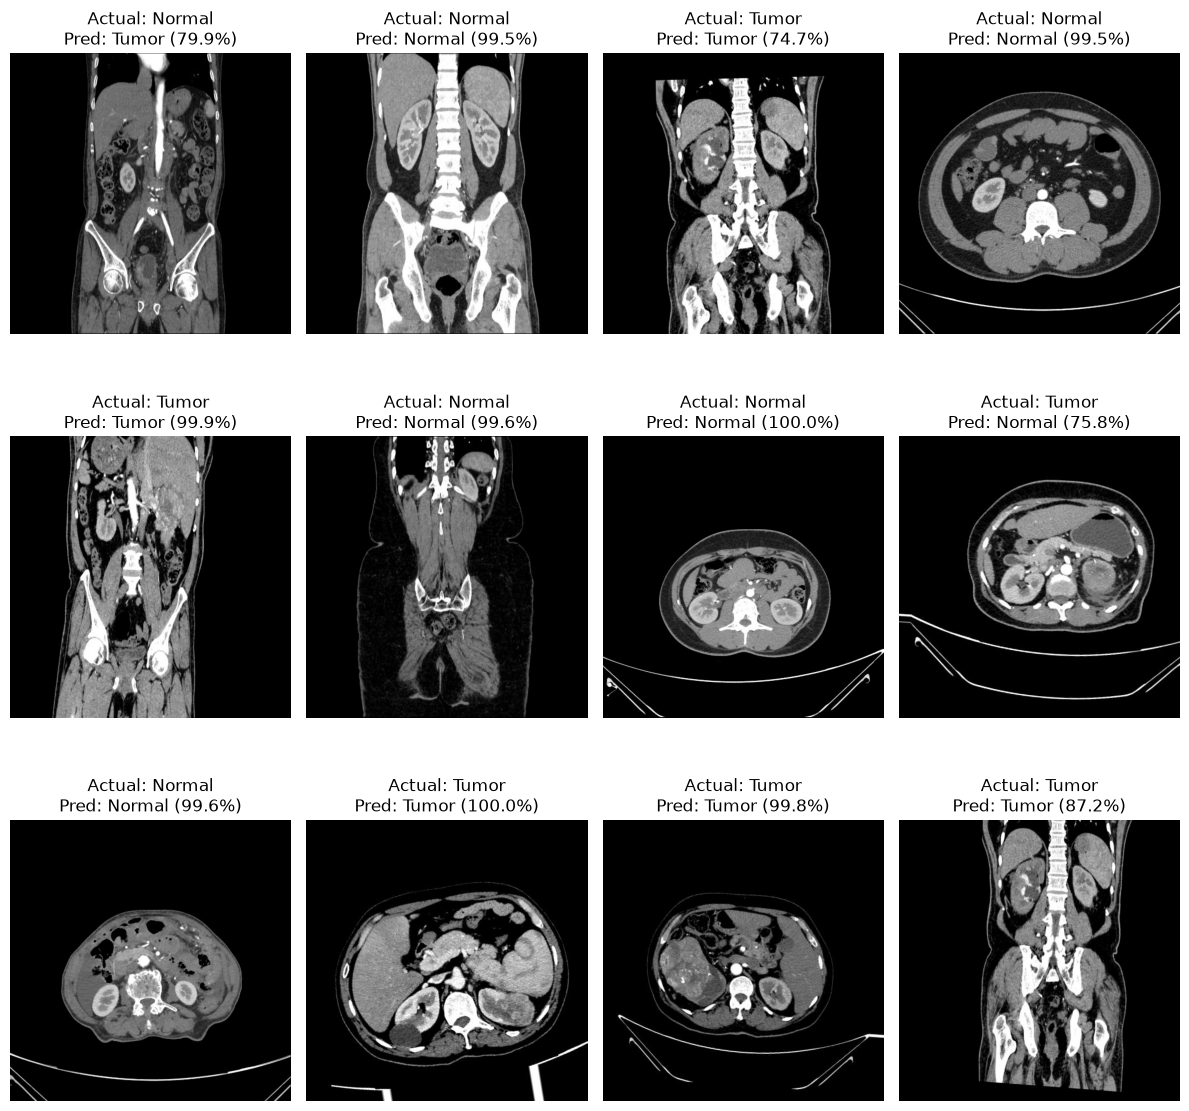

In [35]:
import matplotlib.pyplot as plt
import math

sample_images = X_test[:12]

plt.figure(figsize=(12, 12))

for i, image_path in enumerate(sample_images):

    prediction, confidence = predict_kidney_image(image_path)

    actual_class = os.path.basename(
        os.path.dirname(image_path)
    )

    image = Image.open(image_path)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image, cmap="gray")
    plt.axis("off")

    plt.title(
        f"Actual: {actual_class}\n"
        f"Pred: {prediction} ({confidence * 100:.1f}%)"
    )

plt.tight_layout()
plt.show()